Import Libraries and Load Dataset

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer

df = pd.read_csv("FakeNewsNet.csv")

df.head()

,title,news_url,source_domain,tweet_num,real
0,Kandi Burruss Explodes Over Rape Accusation on...,http://toofab.com/2017/05/08/real-housewives-a...,toofab.com,42,1
1,People's Choice Awards 2018: The best red carp...,https://www.today.com/style/see-people-s-choic...,www.today.com,0,1
2,Sophia Bush Sends Sweet Birthday Message to 'O...,https://www.etonline.com/news/220806_sophia_bu...,www.etonline.com,63,1
3,Colombian singer Maluma sparks rumours of inap...,https://www.dailymail.co.uk/news/article-33655...,www.dailymail.co.uk,20,1
4,Gossip Girl 10 Years Later: How Upper East Sid...,https://www.zerchoo.com/entertainment/gossip-g...,www.zerchoo.com,38,1


Text Preprocessing

In [2]:
def preprocess_text(text):

    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)

    words = text.split()

    return words

df = df.dropna(subset=['title', 'real'])

df['tokens'] = df['title'].apply(preprocess_text)

display(df[['title', 'tokens']].head())

,title,tokens
0,Kandi Burruss Explodes Over Rape Accusation on...,"[kandi, burruss, explodes, over, rape, accusat..."
1,People's Choice Awards 2018: The best red carp...,"[peoples, choice, awards, the, best, red, carp..."
2,Sophia Bush Sends Sweet Birthday Message to 'O...,"[sophia, bush, sends, sweet, birthday, message..."
3,Colombian singer Maluma sparks rumours of inap...,"[colombian, singer, maluma, sparks, rumours, o..."
4,Gossip Girl 10 Years Later: How Upper East Sid...,"[gossip, girl, years, later, how, upper, east,..."


Create Word Vocabulary

In [3]:
all_words = [
    word
    for sentence in df['tokens']
    for word in sentence
]

word_counts = pd.Series(all_words).value_counts()

vocabulary = word_counts.index.tolist()

word_to_id = {
    word: i for i, word in enumerate(vocabulary)
}

print("Vocabulary Size:", len(vocabulary))

Vocabulary Size: 19135


Generate Word-Context Pairs

In [4]:
window_size = 2

training_pairs = []

for sentence in df['tokens']:

    for i, target in enumerate(sentence):

        for j in range(
            max(0, i - window_size),
            min(len(sentence), i + window_size + 1)
        ):

            if i != j:

                training_pairs.append((
                    word_to_id[target],
                    word_to_id[sentence[j]]
                ))

pairs = np.array(training_pairs)

print("Total Training Pairs:", len(pairs))

print("Sample Word-Context Pairs:")

for target, context in pairs[:10]:
    print(vocabulary[target], "->", vocabulary[context])

Total Training Pairs: 867618
Sample Word-Context Pairs:
kandi -> burruss
kandi -> explodes
burruss -> kandi
burruss -> explodes
burruss -> over
explodes -> kandi
explodes -> burruss
explodes -> over
explodes -> rape
over -> burruss


Create Word-Context Matrix

In [5]:
vocab_size = len(vocabulary)

co_matrix = np.zeros(
    (vocab_size, vocab_size),
    dtype=np.float32
)

for target, context in pairs:

    co_matrix[target, context] += 1

print("Word-Context Matrix Shape:", co_matrix.shape)

Word-Context Matrix Shape: (19135, 19135)


Generate Word Embeddings Using SVD

In [6]:
if vocab_size >= 3:

    n_components = min(50, vocab_size - 1)

    svd = TruncatedSVD(
        n_components=n_components,
        random_state=42
    )

    word_embeddings = svd.fit_transform(co_matrix)

else:
    word_embeddings = co_matrix

print("Word Embedding Shape:", word_embeddings.shape)

Word Embedding Shape: (19135, 50)


Find Similar Words

In [7]:
from sklearn.metrics.pairwise import cosine_similarity

def find_similar_words(word, top_n=5):

    if word not in word_to_id:
        print("Word not found in vocabulary")
        return

    word_id = word_to_id[word]

    similarities = cosine_similarity(
        word_embeddings[word_id].reshape(1, -1),
        word_embeddings
    )[0]

    similar_ids = np.argsort(similarities)[::-1]

    results = []

    for idx in similar_ids:

        if idx != word_id:

            results.append({
                'Word': vocabulary[idx],
                'Similarity': round(similarities[idx], 4)
            })

        if len(results) == top_n:
            break

    return pd.DataFrame(results)


find_similar_words("president")

,Word,Similarity
0,holiday,0.9530
1,office,0.9397
2,challenge,0.9337
3,season,0.9320
4,show,0.9285


Compare Fake and Real News Vocabulary

In [8]:
fake_words = [
    word
    for sentence in df[df['real'] == 0]['tokens']
    for word in sentence
]

real_words = [
    word
    for sentence in df[df['real'] == 1]['tokens']
    for word in sentence
]

print("Top Words in Fake News:")

display(pd.Series(fake_words).value_counts().head(15))

print("Top Words in Real News:")

display(pd.Series(real_words).value_counts().head(15))

Top Words in Fake News:


to            1337
and           1191
the           1026
with           757
is             721
a              686
of             686
in             646
on             592
for            563
jennifer       479
her            458
kardashian     422
brad           411
after          354
Name: count, dtype: int64

Top Words in Real News:


the      5212
and      3770
to       3415
of       2565
in       2473
a        2284
on       2105
her      1860
with     1821
for      1775
is       1654
at       1308
after    1010
new       826
from      752
Name: count, dtype: int64

Visualize Word Embeddings Using PCA

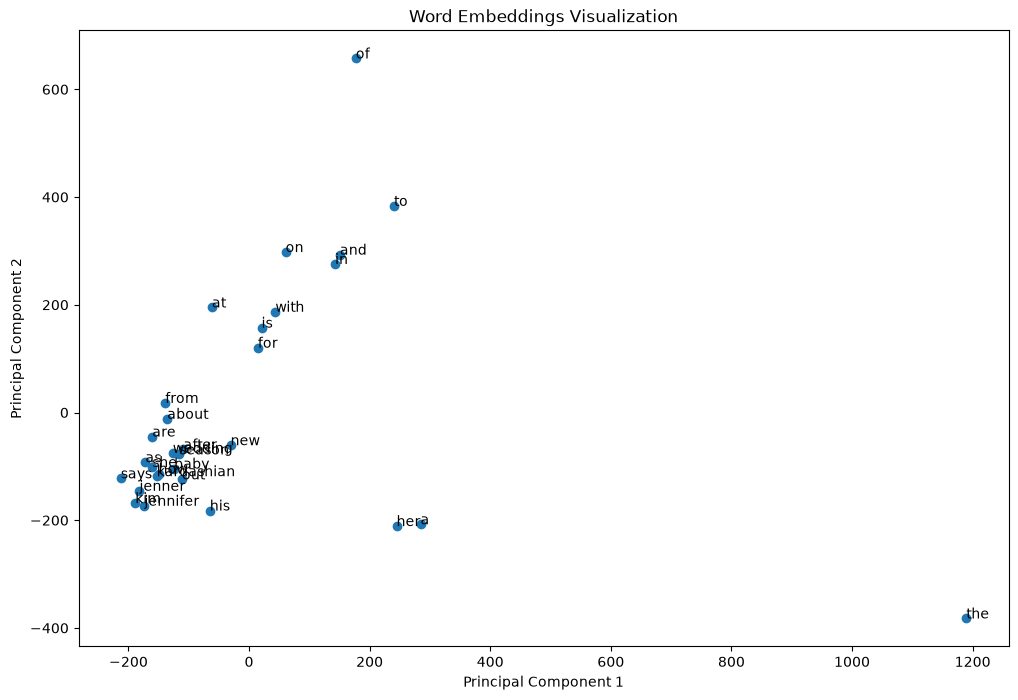

In [9]:
from sklearn.decomposition import PCA

top_words = vocabulary[:30]

vectors = np.array([
    word_embeddings[word_to_id[word]]
    for word in top_words
])

if vectors.shape[1] >= 2:

    pca = PCA(n_components=2)

    reduced = pca.fit_transform(vectors)

    plt.figure(figsize=(12, 8))

    plt.scatter(reduced[:, 0], reduced[:, 1])

    for i, word in enumerate(top_words):

        plt.annotate(
            word,
            (reduced[i, 0], reduced[i, 1])
        )

    plt.title("Word Embeddings Visualization")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")

    plt.show()

Final Results

In [10]:
print("WORD EMBEDDING ANALYSIS")

print("Total Articles:", len(df))

print("Vocabulary Size:", vocab_size)

print("Training Pairs:", len(pairs))

print("Embedding Dimensions:", word_embeddings.shape[1])

print("\nSample Word Embeddings:")

for word in vocabulary[:5]:

    print(word, word_embeddings[word_to_id[word]][:5])

WORD EMBEDDING ANALYSIS
Total Articles: 23196
Vocabulary Size: 19135
Training Pairs: 867618
Embedding Dimensions: 50

Sample Word Embeddings:
the [1147.5099   -853.882    -229.0208   -169.71686   -82.944756]
and [ 599.814    206.29686  358.64478 -161.97148 -391.54483]
to [703.7504   250.30846   40.008026 270.1665   -84.97216 ]
of [ 739.2367   533.7478  -187.59375 -165.51826  120.13302]
in [564.22626  208.78896  -78.313324  24.284107  62.963993]
